# 10) Example of CNN on ImageNet dataset

Important points of the notebook:

- classic CNN model is prone to overfitting and low accuracy.

Rmk) To run cells, cuda is necessary.

## Import ImageNet dataset

In [49]:
from pathlib import Path
import tarfile
import urllib.request

In [50]:
dataset_dir = Path.cwd() / 'imagenette2-160'
if not (dataset_dir / 'train').is_dir():
    archive_path = Path.cwd() / 'imagenette2-160.tgz'
    if not archive_path.exists():
        url = 'https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz'
        print('Downloading Imagenette...')
        urllib.request.urlretrieve(url, archive_path)
    print('Extracting Imagenette...')
    with tarfile.open(archive_path, 'r:gz') as archive:
        archive.extractall(Path.cwd())

train_dir = dataset_dir / 'train'
if not train_dir.is_dir():
    raise FileNotFoundError(f'Could not find the training folder: {train_dir}')

class_ids = sorted(
    folder.name
    for folder in train_dir.iterdir()
    if folder.is_dir() and not folder.name.startswith('.')
)

In [51]:
import os
from random import choice
from PIL import Image

In [52]:
class_ids = sorted(
    folder
    for folder in os.listdir("imagenette2-160/train")
    if not folder.startswith(".")
)

In [53]:
def load_one(class_name):
    files = os.listdir(f"imagenette2-160/train/{class_name}")
    return PIL.Image.open(
        f"imagenette2-160/train/{class_name}/{choice(files)}"
    )

In [54]:
class_names = [
    "Tanche",
    "Springer anglais",
    "Radiocassette",
    "Tronçonneuse",
    "Église",
    "Cor d'harmonie",
    "Camion poubelle",
    "Pompe à essence",
    "Balle de golf",
    "Parachute",
]

'Tanche'

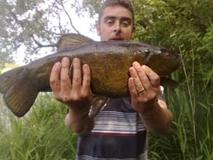

'Springer anglais'

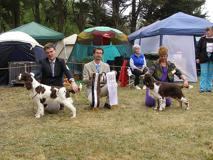

'Radiocassette'

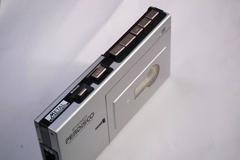

'Tronçonneuse'

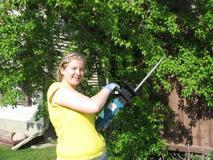

'Église'

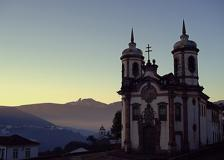

"Cor d'harmonie"

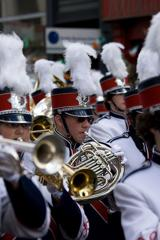

'Camion poubelle'

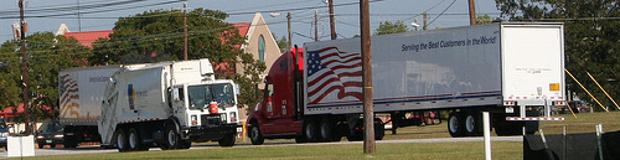

'Pompe à essence'

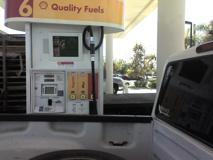

'Balle de golf'

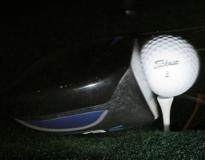

'Parachute'

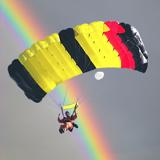

In [55]:
for class_name, class_id in zip(class_names, class_ids):
    display(class_name)
    display(load_one(class_id))

## Dataset, Subsets, Dataloader

As usual.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

In [ ]:
class ImageNetteDataset(Dataset):
    def __init__(self, train_or_val, class_ids=class_ids):
        self.class_ids = class_ids
        self.filenames = []
        self.labels = []

        for class_number, class_id in enumerate(class_ids):
            folder = os.path.join("imagenette2-160", train_or_val, class_id)

            for filename in os.listdir(folder):
                if not filename.startswith("."):
                    self.filenames.append(os.path.join(folder, filename))
                    self.labels.append(class_number)

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        image = Image.open(self.filenames[idx]).convert("RGB")

        width, height = image.size
        left = (width - 160) // 2
        top = (height - 160) // 2
        image = image.crop((left, top, left + 160, top + 160))

        image_tensor = torch.tensor(np.asarray(image)) / 255.0
        return image_tensor, self.labels[idx]


In [ ]:
train_dataset = ImageNetteDataset("train")
valid_dataset = ImageNetteDataset("val")

In [ ]:
train_dataloader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    drop_last=True,
)

valid_dataloader = DataLoader(
    valid_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    drop_last=False,
)

In [ ]:
batch = next(iter(train_dataloader))
print(len(batch))
print(batch[0].shape)
print(batch[1].shape)

## Functions for training and validation

In [ ]:
from tqdm import tqdm, trange
from sklearn.metrics import accuracy_score

In [ ]:
# INITIALISE PARAMETERS

def init_param(modele):
    """
    Réinitialise les paramètres des couches du modèle.
    """
    for m in modele.modules():
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(
                m.weight,
                mode="fan_out",
                nonlinearity="relu",
            )
            if m.bias is not None:
                nn.init.constant_(m.bias, 0)
        elif isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, 0, 0.01)
            if m.bias is not None:
                nn.init.constant_(m.bias, 0)

In [ ]:
# CHECK GPU

def check_gpu(modele):
    if torch.cuda.is_available():
        device = torch.device("cuda")
    else:
        device = torch.device("cpu")

    return modele.to(device), device

In [ ]:
# SINGLE TRAINING

def entrainement_epoque(modele, train_dataloader, device, lr=1e-5):
    loss_function = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(modele.parameters(), lr=lr)

    modele.train()
    train_loss = []
    train_accuracy = []

    for images, labels in tqdm(train_dataloader, leave=False):
        optimizer.zero_grad()

        y_pred = modele(images.permute([0, 3, 1, 2]).to(device))
        loss_result = loss_function(y_pred, labels.to(device))

        loss_result.backward()

        train_loss.append(loss_result.detach().cpu().numpy())
        train_accuracy.append(
            np.mean(
                np.argmax(y_pred.detach().cpu().numpy(), axis=1)
                == labels.numpy()
            )
        )

        optimizer.step()

    return train_loss, train_accuracy


In [ ]:
# SINGLE VALIDATION

def validation(modele, valid_dataloader, device):
    loss_function = nn.CrossEntropyLoss()
    modele.eval()

    all_preds = []
    all_labels = []
    epoch_valid_loss = 0.0

    with torch.no_grad():
        for images, labels in tqdm(valid_dataloader, leave=False):
            y_pred = modele(images.permute([0, 3, 1, 2]).to(device))
            loss_result = loss_function(y_pred, labels.to(device))

            epoch_valid_loss += loss_result.detach().cpu().numpy()
            all_preds.extend(
                np.argmax(y_pred.detach().cpu().numpy(), axis=1)
            )
            all_labels.extend(labels.numpy())

    return (
        epoch_valid_loss / len(valid_dataloader),
        accuracy_score(all_labels, all_preds),
    )


In [ ]:
# PLOT LOSS FUNCTION

def plot_results(train_perte, train_accuracy, valid_perte, valid_accuracy):
    _, axes = plt.subplots(1, 2, figsize=(20, 8))
    plt.rcParams["font.size"] = 20

    n = len(train_dataloader)
    rng = range(n, n * len(valid_accuracy) + 1, n)

    axes[0].plot(train_perte, label="train")
    axes[0].plot(rng, valid_perte, label="valid", linewidth=4)
    axes[0].legend()
    axes[0].set_ylim([0, 3.5])
    axes[0].set_title(
        f"Fonction de perte, min = {min(valid_perte):.2f}"
    )

    axes[1].plot(train_accuracy, label="train")
    axes[1].plot(rng, valid_accuracy, label="valid", linewidth=4)
    axes[1].legend()
    axes[1].set_title(
        f"Accuracy, max = {max(valid_accuracy):.1%}"
    )


In [ ]:
# TRAINING AND VALIDATION

def train(modele, epoques, lr, do_init=True):
    if do_init:
        init_param(modele)

    modele, device = check_gpu(modele)

    train_perte = []
    train_accuracy = []
    valid_perte = []
    valid_accuracy = []

    with trange(epoques) as progress_bar:
        for epoque in progress_bar:
            perte_epoque, accuracy_epoque = entrainement_epoque(
                modele,
                train_dataloader,
                device,
                lr,
            )
            train_perte.extend(perte_epoque)
            train_accuracy.extend(accuracy_epoque)

            perte, accuracy = validation(
                modele,
                valid_dataloader,
                device,
            )
            valid_perte.append(perte)
            valid_accuracy.append(accuracy)

            progress_bar.set_description(
                f"Train : perte {np.mean(train_perte):.2f} "
                f"accuracy {np.mean(train_accuracy):.1%} "
                f"Valid : perte {perte:.2f} "
                f"accuracy {accuracy:.1%}"
            )

    plot_results(
        train_perte,
        train_accuracy,
        valid_perte,
        valid_accuracy,
    )

    return train_perte, train_accuracy, valid_perte, valid_accuracy


## Classic CNN model: prone to *overfitting* and *low accuracy*

In [ ]:
# EXAMPLE OF CNNs MODEL

model = nn.Sequential(
    nn.Conv2d(3, 32, 3),      # 1st convolutional layer
    nn.MaxPool2d(2),          # max pooling: on 2x2 grids save the max value
    nn.ReLU(),                # activation function

    nn.Conv2d(32, 64, 3),     # 2nd convolutional layer
    nn.Flatten(),             # flatten: transforms the array into a vector (last step before output layer)
    nn.ReLU(),                # activation function

    nn.Linear(379456, 10)     # output
)

In [ ]:
# Training and validation results
train_perte, train_accuracy, valid_perte, valid_accuracy = train(
    model,
    30,
    1e-4,
)

In [ ]:
from IPython.display import Image
Image('resultat_modele_base.png', width=1200)

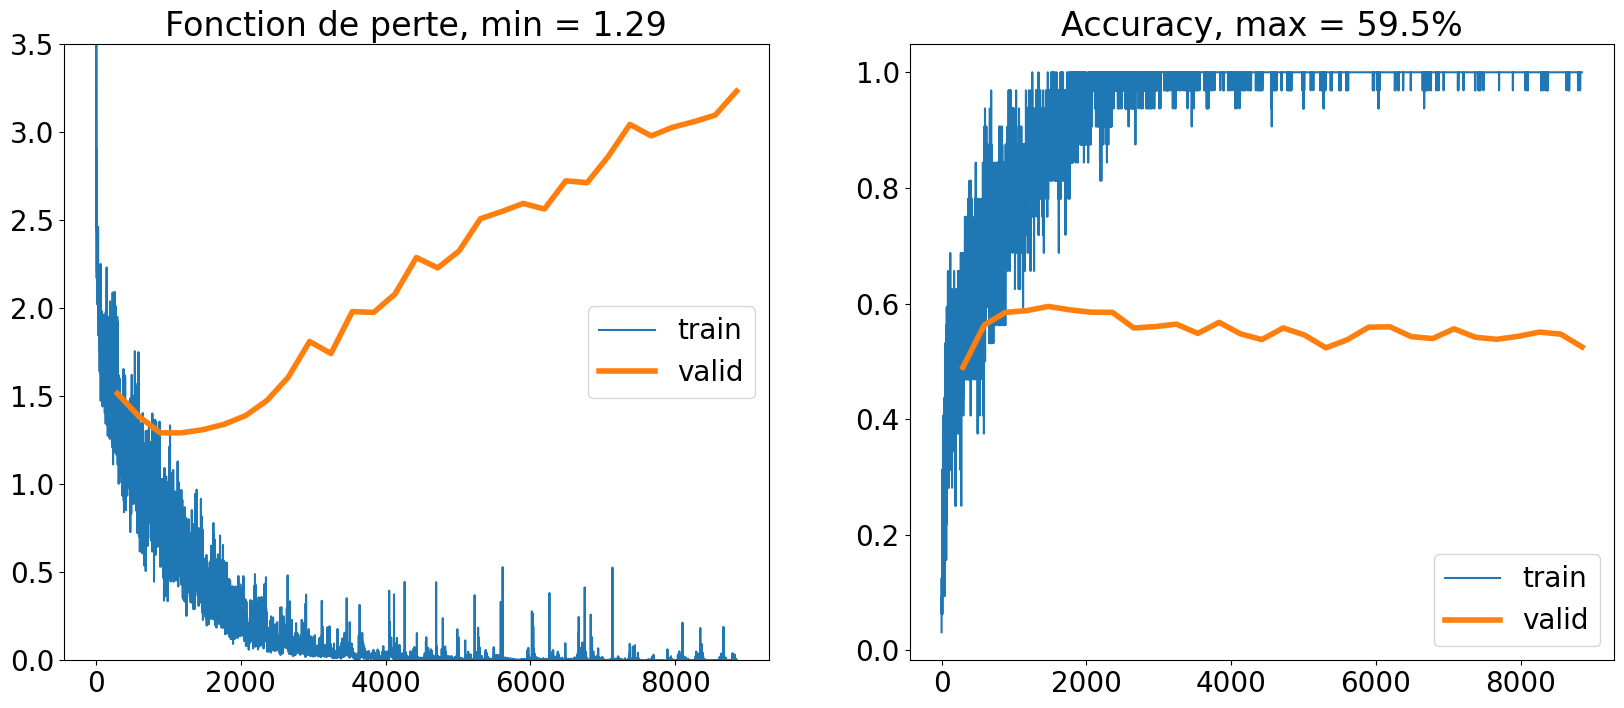

**Using a classic CNN model: overfitting**:

- there is a huge gap between the loss function computed on the training set and on the validation set;
- the loss on the training set decreases to zero, meaning that the model learns very well on the training set;
- the loss on the validation set increases, meaning that the model learns very badly on the validation set.

We have overfitting we the model learns too well on the training set and is not able to generalise to new data.

**and low accuracy**:

- the accuracy on the training set increases to 100% as the number of epochs increases;
- the accuracy on the validation set remains low around 60% and it's very unstable.

> Rmk) *It is okay to have some overfitting, if the accuracy on the validation set is high!!*

It is more important that the model predicts the correct class, than its confidence.

However, in our case, the accuracy on the validation is low around 60% and we can say that absolutely this model does not learn well.

*Accuracy*: correctness of prediction.

*Loss*: how good is the model at prediction.

Rmk) *Baseline loss*: for $K$ classes, assign the same probability of predicting each class, i.e. $p_i = \dfrac{1}{K}$ for true labels $y_i$. Therefore, the baseline loss is
$$
L = - \sum_{i=1}^{K} y_i\log(p_i) =- log\left( \dfrac{1}{K} \right) = log\left(K\right).
$$

This loss is chosen when the model has no idea of predictions.